MLPDataset slide-transition EDA. Source: https://github.com/mlpdataset/MLPDataset at commit 0e5ceabc29e381f52b70383c23a2c32a2dd47962. Official public archive: https://drive.google.com/file/d/1amyxxy4reuHGQ3FaKLE5bYzVxD7DOl7K/view . Analyze manually annotated slide transitions only; this is not generic scene-cut or chapter GT. The notebook records source accounting, quality flags, plots, examples and a decision. Do not interpret missing media as inspected media.

In [1]:
from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter
from datetime import datetime, timezone
from hashlib import sha256
import io, json, re, subprocess, sys, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown"])
    import gdown

SOURCE_ID = "1amyxxy4reuHGQ3FaKLE5bYzVxD7DOl7K"
SOURCE_URL = f"https://drive.google.com/file/d/{SOURCE_ID}/view"
SOURCE_REPO_COMMIT = "0e5ceabc29e381f52b70383c23a2c32a2dd47962"
EXPECTED_SHA256 = "dbd07ef37de603a22abb7be7d81245034b3c487f4878227cbef36ae3d451cfa7"
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "docs" / "BENCHMARK.md").exists()), None)
output_dir = (root / "experiments" / "outputs" / "mlp_eda_source") if root else (Path.cwd() / "mlp_eda_source")
output_dir.mkdir(parents=True, exist_ok=True)
archive = output_dir / "mlp_anon.zip"
if not archive.exists():
    downloaded = gdown.download(id=SOURCE_ID, output=str(archive), quiet=False)
    if not downloaded:
        raise RuntimeError("Official archive download failed; EDA HOLD.")
archive_sha256 = sha256(archive.read_bytes()).hexdigest()
assert archive_sha256 == EXPECTED_SHA256, f"Archive changed: {archive_sha256}; review before using results."
print({"download_url": SOURCE_URL, "source_repo_commit": SOURCE_REPO_COMMIT,
       "archive": str(archive), "bytes": archive.stat().st_size, "sha256": archive_sha256,
       "observed_at_utc": datetime.now(timezone.utc).isoformat()})

{'download_url': 'https://drive.google.com/file/d/1amyxxy4reuHGQ3FaKLE5bYzVxD7DOl7K/view', 'source_repo_commit': '0e5ceabc29e381f52b70383c23a2c32a2dd47962', 'archive': 'C:\\Users\\hung\\Documents\\GitHub\\multimodal-lecture-summarizer\\benchmark\\experiments\\outputs\\mlp_eda_source\\mlp_anon.zip', 'bytes': 138163175, 'sha256': 'dbd07ef37de603a22abb7be7d81245034b3c487f4878227cbef36ae3d451cfa7', 'observed_at_utc': '2026-10-10T06:21:00.039046+00:00'}


In [2]:
z = zipfile.ZipFile(archive)
members = z.infolist()
unsafe = [i.filename for i in members if PurePosixPath(i.filename).is_absolute()
          or ".." in PurePosixPath(i.filename).parts or "\\" in i.filename]
if unsafe:
    raise ValueError(f"Unsafe ZIP paths: {unsafe[:5]}")
bad_crc = z.testzip()
if bad_crc:
    raise ValueError(f"ZIP CRC failure: {bad_crc}")
names = set(z.namelist())
by_parent = defaultdict(list)
for item in members:
    by_parent[str(PurePosixPath(item.filename).parent)].append(item)
extensions = Counter(PurePosixPath(i.filename).suffix.lower() for i in members if not i.is_dir())
media_names = sorted(n for n in names if n.lower().endswith((".jpg", ".jpeg", ".png", ".webp", ".mp4", ".mkv")))
display(pd.DataFrame([{"archive_members": len(members),
                       "uncompressed_bytes": sum(i.file_size for i in members),
                       "segments_txt": sum(n.endswith("/segments.txt") for n in names),
                       "slide_spoken_csv": sum(n.endswith("_spoken.csv") for n in names),
                       "images_or_videos": len(media_names), "crc": "PASS",
                       "extraction": "none; read in ZIP"}]))
display(pd.DataFrame(extensions.most_common(), columns=["suffix", "files"]))
print("Archive is not extracted. Path traversal is rejected; all files are read inside the CRC-checked ZIP.")

Archive is not extracted. Path traversal is rejected; all files are read inside the CRC-checked ZIP.


,archive_members,uncompressed_bytes,segments_txt,slide_spoken_csv,images_or_videos,crc,extraction
0,28207,1021727742,332,9021,0,PASS,none; read in ZIP


,suffix,files
0,.csv,27441
1,.txt,332
2,.json,30
3,,17
4,.ipynb,8


In [3]:
raw = pd.read_csv(io.BytesIO(z.read("data/raw_video_links.csv")))
required = {"speaker", "video_id", "seconds", "youtube_url"}
assert required <= set(raw.columns), f"Missing metadata columns: {required - set(raw.columns)}"
raw["video_key"] = raw["video_id"].astype(str).str.removesuffix(".mp4")
raw["seconds"] = pd.to_numeric(raw["seconds"], errors="coerce")
assert not raw["video_key"].duplicated().any(), "Duplicate video IDs require manual join review"
by_video = raw.set_index("video_key")
lecture_rows, boundary_rows, parse_failures = [], [], []
for segment_name in sorted(n for n in names if n.endswith("/segments.txt")):
    folder = str(PurePosixPath(segment_name).parent)
    speaker = PurePosixPath(folder).parts[1]
    siblings = by_parent[folder]
    transcript_files = [i.filename for i in siblings if i.filename.endswith("_transcripts.csv")]
    video_key = (PurePosixPath(transcript_files[0]).name.removesuffix("_transcripts.csv")
                 if len(transcript_files) == 1 else None)
    meta = by_video.loc[video_key] if video_key in by_video.index else None
    duration = float(meta["seconds"]) if meta is not None else np.nan
    lines = z.read(segment_name).decode("utf-8-sig", "replace").splitlines()
    times = []
    for line_no, value in enumerate(lines, start=1):
        if not value.strip():
            continue
        try:
            times.append(float(value.strip()))
        except ValueError:
            parse_failures.append({"folder": folder, "line": line_no, "value": value[:80]})
    spoken_count = sum(bool(re.fullmatch(r"slide_\d+_spoken\.csv", PurePosixPath(i.filename).name))
                       for i in siblings)
    lecture_rows.append({"folder": folder, "speaker": speaker, "video_key": video_key,
                         "transcripts": len(transcript_files), "boundaries": len(times),
                         "spoken_csv": spoken_count, "video_seconds": duration,
                         "source_url": meta["youtube_url"] if meta is not None else None,
                         "first_boundary": times[0] if times else np.nan,
                         "last_boundary": times[-1] if times else np.nan})
    for idx, t in enumerate(times):
        gap = (times[idx + 1] - t) if idx + 1 < len(times) else np.nan
        boundary_rows.append({"folder": folder, "speaker": speaker, "video_key": video_key,
                              "index": idx, "time_s": t, "next_gap_s": gap,
                              "nonincrease": bool(idx and t <= times[idx - 1]),
                              "after_video_s": max(0.0, t - duration) if np.isfinite(duration) else np.nan})
lectures = pd.DataFrame(lecture_rows)
boundaries = pd.DataFrame(boundary_rows)
missing_video_ids = sorted(set(raw.video_key) - set(lectures.video_key.dropna()))
print({"source_video_rows": len(raw), "folders_with_segments": len(lectures),
       "boundary_rows": len(boundaries), "unmatched_source_video_ids": len(missing_video_ids),
       "invalid_numeric_lines": len(parse_failures)})
display(pd.DataFrame({"missing_video_id": missing_video_ids}))
display(pd.DataFrame(parse_failures).head(20))

{'source_video_rows': 333, 'folders_with_segments': 332, 'boundary_rows': 9021, 'unmatched_source_video_ids': 1, 'invalid_numeric_lines': 0}


,missing_video_id
0,aXxRSrIcGjU


""


In [4]:
speaker_summary = lectures.groupby("speaker", as_index=False).agg(
    lectures=("folder", "size"), boundaries=("boundaries", "sum"),
    spoken_csv=("spoken_csv", "sum"), empty_segments=("boundaries", lambda s: int((s == 0).sum())))
display(speaker_summary)
quality = pd.DataFrame([{
    "source_video_rows": len(raw), "matched_lectures": int(lectures.video_key.notna().sum()),
    "empty_segments_files": int((lectures.boundaries == 0).sum()),
    "boundary_to_spoken_count_mismatch": int((lectures.boundaries != lectures.spoken_csv).sum()),
    "nonincreasing_boundary_rows": int(boundaries.nonincrease.sum()),
    "beyond_duration_gt_0s": int((boundaries.after_video_s > 0).sum()),
    "beyond_duration_gt_0_05s": int((boundaries.after_video_s > 0.05).sum()),
    "media_files_in_archive": len(media_names),
    "metadata_video_id_duplicates": int(raw.video_key.duplicated().sum()),
}])
display(quality)
display(lectures[lectures.boundaries == 0][["folder", "video_key", "boundaries", "spoken_csv"]])
display(boundaries[(boundaries.nonincrease) | (boundaries.after_video_s > 0.05)]
        [["video_key", "index", "time_s", "next_gap_s", "nonincrease", "after_video_s"]].head(25))

,speaker,lectures,boundaries,spoken_csv,empty_segments
0,anat-1,21,1153,1153,1
1,anat-2,3,84,84,0
2,bio-1,19,950,950,0
3,bio-3,11,655,655,0
4,bio-4,28,1272,1272,0
5,dental,189,2607,2607,5
6,ml-1,15,900,900,0
7,psy-1,8,138,138,0
8,psy-2,14,275,275,0
9,speaking,24,987,987,0


,source_video_rows,matched_lectures,empty_segments_files,boundary_to_spoken_count_mismatch,nonincreasing_boundary_rows,beyond_duration_gt_0s,beyond_duration_gt_0_05s,media_files_in_archive,metadata_video_id_duplicates
0,333,332,6,0,15,4,0,0,0


,folder,video_key,boundaries,spoken_csv
20,data/anat-1/AnatomyPhysiology/30,BxV06Zn0Kck,0,0
121,data/dental/NBDEPartI/03,DBnCAfsJwVA,0,0
122,data/dental/NBDEPartI/04,vpg6BkvwOgM,0,0
125,data/dental/NBDEPartI/07,ZZFVEt9de00,0,0
128,data/dental/NBDEPartI/10,mw9aS1fkkCo,0,0
129,data/dental/Occlusion/2,0G6xEWOUs1E,0,0


,video_key,index,time_s,next_gap_s,nonincrease,after_video_s
45,_yre2uKcj7A,17,1570.5000,117.5000,True,0.0
348,3ZA33n7BrRg,13,743.4998,40.5000,True,0.0
2316,DZSEErNZ1d4,9,490.7597,47.9999,True,0.0
2328,DZSEErNZ1d4,21,976.4894,-0.0001,True,0.0
2329,DZSEErNZ1d4,22,976.4893,41.0000,True,0.0
2347,DZSEErNZ1d4,40,1817.4892,43.0000,True,0.0
2367,DZSEErNZ1d4,60,2871.9889,60.0000,True,0.0
4353,NQtXvfJCtxo,2,77.4999,36.0000,True,0.0
4585,1LmKuxUzGUw,1,7.6068,42.0000,True,0.0
5065,-a5-EHnZ_XA,6,355.4221,2.0000,True,0.0


Metadata and boundary timing only; no source frame was decoded.


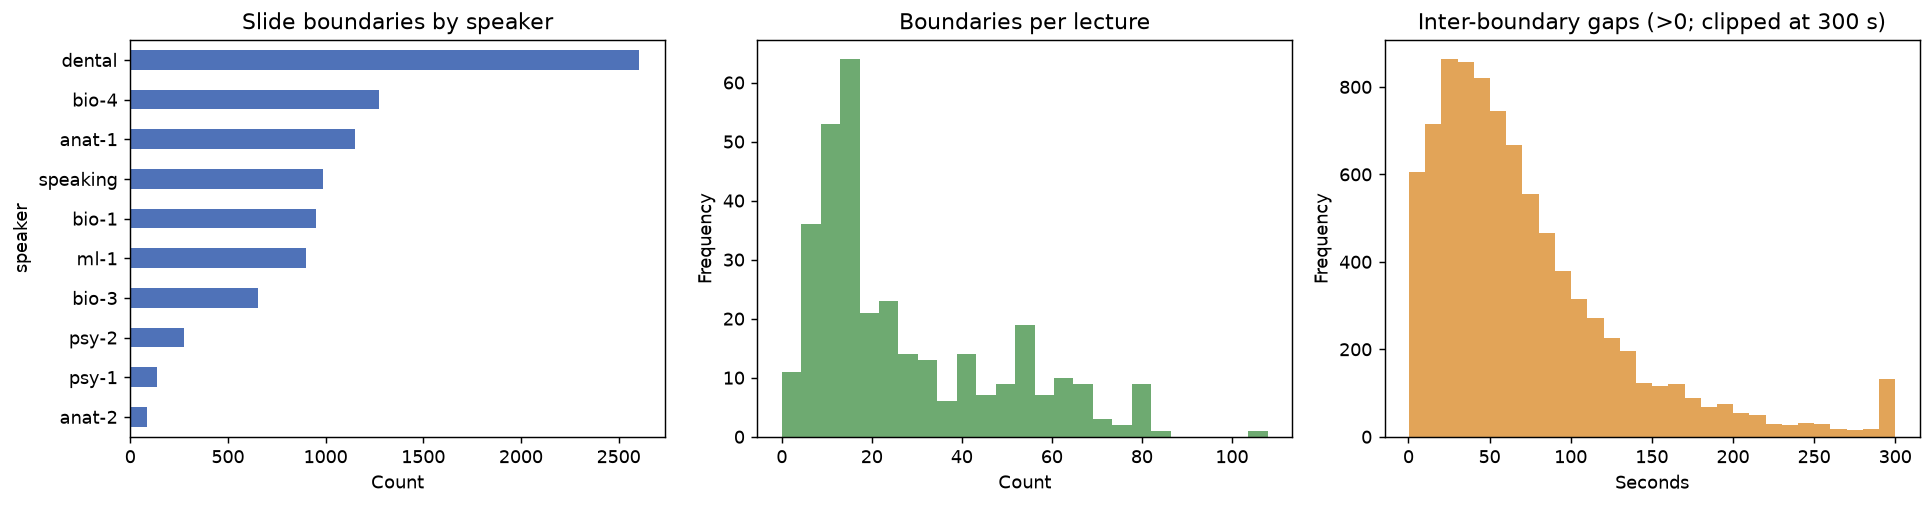

,metric,n,p05,median,p95
0,boundaries_per_video,332,5.00000,18.0,68.450000
1,positive_inter_boundary_gap_s,8680,7.18217,56.5,196.443665


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
speaker_summary.sort_values("boundaries").plot.barh(x="speaker", y="boundaries", ax=axes[0], legend=False, color="#4f72b8")
axes[0].set_title("Slide boundaries by speaker"); axes[0].set_xlabel("Count")
lectures.boundaries.plot.hist(bins=25, ax=axes[1], color="#6eaa71")
axes[1].set_title("Boundaries per lecture"); axes[1].set_xlabel("Count")
positive_gaps = boundaries.loc[boundaries.next_gap_s > 0, "next_gap_s"]
positive_gaps.clip(upper=300).plot.hist(bins=30, ax=axes[2], color="#e2a458")
axes[2].set_title("Inter-boundary gaps (>0; clipped at 300 s)"); axes[2].set_xlabel("Seconds")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"metric": ["boundaries_per_video", "positive_inter_boundary_gap_s"],
                      "n": [len(lectures), len(positive_gaps)],
                      "p05": [lectures.boundaries.quantile(.05), positive_gaps.quantile(.05)],
                      "median": [lectures.boundaries.median(), positive_gaps.median()],
                      "p95": [lectures.boundaries.quantile(.95), positive_gaps.quantile(.95)]}))
print("Metadata and boundary timing only; no source frame was decoded.")

In [6]:
json_rows = []
for speaker in sorted(lectures.speaker.unique()):
    path = f"data/{speaker}/{speaker}.json"
    if path not in names:
        json_rows.append({"speaker": speaker, "status": "missing", "records": np.nan, "linked_spoken": np.nan})
        continue
    try:
        data = json.loads(z.read(path))
        linked = 0
        malformed_scene = 0
        for record in data.values():
            scene = record.get("scene_id") if isinstance(record, dict) else None
            if not isinstance(scene, list) or len(scene) != 3:
                malformed_scene += 1
                continue
            spoken = f"data/{speaker}/{scene[0]}/{scene[1]}/{scene[2]}_spoken.csv"
            linked += spoken in names
        json_rows.append({"speaker": speaker, "status": "parsed", "records": len(data),
                          "linked_spoken": linked, "malformed_scene_id": malformed_scene})
        del data
    except (json.JSONDecodeError, UnicodeDecodeError, MemoryError) as exc:
        json_rows.append({"speaker": speaker, "status": type(exc).__name__,
                          "records": np.nan, "linked_spoken": np.nan, "error": str(exc)[:160]})
json_audit = pd.DataFrame(json_rows)
display(json_audit)
print("Malformed JSON is reported rather than silently substituted with counts from other files.")

Malformed JSON is reported rather than silently substituted with counts from other files.


,speaker,status,records,linked_spoken,malformed_scene_id,error
0,anat-1,parsed,1142.0,1142.0,0.0,NaN
1,anat-2,parsed,84.0,84.0,0.0,NaN
2,bio-1,parsed,717.0,717.0,0.0,NaN
3,bio-3,parsed,629.0,629.0,0.0,NaN
4,bio-4,parsed,1258.0,1258.0,0.0,NaN
5,dental,JSONDecodeError,NaN,NaN,NaN,Expecting property name enclosed in double quotes: line 5120653 column 15 (char 131727360)
6,ml-1,parsed,894.0,894.0,0.0,NaN
7,psy-1,parsed,138.0,138.0,0.0,NaN
8,psy-2,parsed,275.0,275.0,0.0,NaN
9,speaking,parsed,959.0,959.0,0.0,NaN


In [7]:
examples = boundaries.sort_values(["video_key", "index"]).groupby("speaker", sort=True).head(1)
examples = examples.merge(lectures[["folder", "source_url"]], on="folder", how="left")
display(examples[["speaker", "video_key", "index", "time_s", "source_url"]].head(10))
image_names = [n for n in media_names if n.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))]
if image_names:
    for path in image_names[:3]:
        display(Markdown("Image from archive: " + path))
        display(Image(data=z.read(path), width=480))
else:
    display(Markdown("**MEDIA HOLD:** No slide images or video in the public ZIP. The fixed-rule first-boundary-per-speaker table above shows metadata examples only; it is not image inspection."))
print("No official slide-boundary train/validation/test split found in archive. Future source-group leakage requires an explicit video-level split.")

No official slide-boundary train/validation/test split found in archive. Future source-group leakage requires an explicit video-level split.


,speaker,video_key,index,time_s,source_url
0,dental,-8QB3Rbeqoc,0,18.7466,https://www.youtube.com/watch?v=-8QB3Rbeqoc
1,bio-4,077X0x07S0c,0,11.0000,https://www.youtube.com/watch?v=077X0x07S0c
2,speaking,0gf3IJFTxEA,0,29.5000,https://www.youtube.com/watch?v=0gf3IJFTxEA
3,psy-1,18SixEz5GDE,0,17.4132,https://www.youtube.com/watch?v=18SixEz5GDE
4,bio-1,2NgUY8f1pa8,0,157.9194,https://www.youtube.com/watch?v=2NgUY8f1pa8
5,anat-1,2U3DsK7BHVU,0,15.8825,https://www.youtube.com/watch?v=2U3DsK7BHVU
6,ml-1,2_dZ5GBlRgU,0,6.5496,https://www.youtube.com/watch?v=2_dZ5GBlRgU
7,psy-2,8OrCdgHcMVM,0,15.1468,https://www.youtube.com/watch?v=8OrCdgHcMVM
8,anat-2,ALRJCeVT0fQ,0,245.7610,https://www.youtube.com/watch?v=ALRJCeVT0fQ
9,bio-3,AS8KJMeiNpM,0,0.0000,https://www.youtube.com/watch?v=AS8KJMeiNpM


<IPython.core.display.Markdown object>

In [8]:
decision = {
    "status": "RESTRICT_ANNOTATION_ONLY_MEDIA_HOLD",
    "dataset": "MLPDataset official mlp_anon.zip",
    "task": "slide transition, not generic scene cut",
    "source_url": SOURCE_URL,
    "source_repo_commit": SOURCE_REPO_COMMIT,
    "archive_sha256": archive_sha256,
    "archive_bytes": archive.stat().st_size,
    "source_video_rows": len(raw),
    "matched_lecture_folders": len(lectures),
    "boundary_rows": len(boundaries),
    "missing_source_video_ids": missing_video_ids,
    "empty_segments_files": int((lectures.boundaries == 0).sum()),
    "nonincreasing_boundary_rows": int(boundaries.nonincrease.sum()),
    "beyond_duration_gt_0_05s": int((boundaries.after_video_s > .05).sum()),
    "images_or_videos_in_archive": len(media_names),
    "json_parse_failures": json_audit.loc[json_audit.status != "parsed", "speaker"].tolist(),
    "limitations": [
        "No slide image or source video in downloaded archive; visual boundary adjudication not run.",
        "No task-specific official split in archive; leakage across a future split not assessed.",
        "ZIP is author-hosted and CRC-valid; YouTube media rights/access and label accuracy need review.",
    ],
}
receipt_path = output_dir / "mlp_slide_transition_eda_receipt.json"
receipt_path.write_text(json.dumps(decision, ensure_ascii=False, indent=2), encoding="utf-8")
print("Receipt:", receipt_path)
display(pd.DataFrame([{"decision": decision["status"], "reason": "Real annotation EDA completed; media and split remain unqualified."}]))
print("Next gate: inspect source video frames, adjudicate abnormal boundaries, freeze video-grouped split before boundary-F1 benchmark.")

Receipt: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\mlp_eda_source\mlp_slide_transition_eda_receipt.json
Next gate: inspect source video frames, adjudicate abnormal boundaries, freeze video-grouped split before boundary-F1 benchmark.


,decision,reason
0,RESTRICT_ANNOTATION_ONLY_MEDIA_HOLD,Real annotation EDA completed; media and split remain unqualified.


## Nhận xét từ bản ZIP đã pin

- 333 video trong bảng nguồn; 332 thư mục lecture có segments.txt và transcript; 1 video không có thư mục segment (aXxRSrIcGjU). Có 9.021 mốc ở 10 nhóm speaker.
- 6 tệp segments rỗng (1 anat-1, 5 dental). Số lượng mốc bằng số tệp slide_*_spoken.csv ở từng thư mục, nhưng sự bằng nhau về số lượng chưa chứng minh nhãn và slide khớp nội dung.
- 15 hàng mốc không tăng (trùng hoặc giảm rất nhỏ); 4 mốc lớn hơn thời lượng trong metadata nhưng sai khác dưới 0,05 giây. Đây là hàng cần xét khi cố định quy tắc loại trừ/tolerance.
- ZIP không có file ảnh/video. dental.json không parse được. Do vậy quyết định hiện tại là RESTRICT cho kiểm kê annotation, HOLD cho xác minh hình ảnh/video và benchmark.
- Không có split chính thức cho tác vụ boundary trong ZIP. Khi tạo cohort sau này, chia theo video/nguồn rồi xét trùng và độ tương tự giữa các nhóm; không gọi một split là unseen nếu đã đọc nhãn của nó ở EDA.


## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

In [9]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "mlpdataset", "observed_at_utc": "2026-10-10T08:57:58.777896+00:00", "counts": {"selected": 333, "observed": 333, "label_valid": 315, "media_valid": 0, "evaluated": 0, "failed": 0, "unit": "source video", "label_valid_definition": "structural annotation only; not independent task GT", "media_valid_definition": "original source videos verified for target endpoint", "failed_definition": "record read/parse failures; HOLD is not a processing failure"}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-id-ledger.csv", "sha256": "760f7589385fd113d3369f9becae69b24616322990b1f7ad0564c7e57fb48119", "rows": 333}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-boundary-ledger.csv", "sha256": "4313fad1ec17bdb4b050022740197dfc7f1fbb996db837f96180a4b32ca41b42", "rows": 9021}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-parse-failures.csv", "sha256": "7eb70257593da06f682a3ddda54a9d260d4fc514f645237f5ca74b08f8da61a6", "rows": 0}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-json-anomalies.csv", "sha256": "899fa8f87cb774b2494c77cb9b0e81a4f90498d4b156e4a3b7d532400b677d45", "rows": 1}], "model_inference_run": false, "unseen_reference_claim": false, "source": {"path": "experiments\\\\outputs\\\\mlp_eda_source\\\\mlp_anon.zip", "sha256": "dbd07ef37de603a22abb7be7d81245034b3c487f4878227cbef36ae3d451cfa7"}, "boundary_records": 9021, "nonincreasing_boundaries": 15, "empty_boundary_files": 6, "json_parse_failures": [{"member": "data/dental/dental.json", "decision": "HOLD", "reason": "Expecting property name enclosed in double quotes: line 5120653 column 15 (char 131727360)"}], "frozen": false, "media_probe_rule": "first released video in sorted source ID order; metadata and 0-20s clip attempt", "endpoint": "slide transition: annotation-only diagnostics; no transition F1 permitted", "blocker": "Original frames, rights and boundary alignment not verified; do not sort annotations as GT.", "source_probes": [{"dataset": "mlpdataset", "id": "-8QB3Rbeqoc", "url": "https://www.youtube.com/watch?v=-8QB3Rbeqoc", "observed_at_utc": "2026-10-10T08:59:02.111497+00:00", "scope": "one deterministic source video; metadata extraction only; no media decoded", "exit_code": 0, "stderr": "", "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-media-probe--8QB3Rbeqoc.txt", "sha256": "ca69b48ad42291d5004820fb124426f76b7b287917a0a136b9ea26602cb85dbb", "duration": 819, "title": "Oral Medicine | ASA Classification | INBDE", "license": null, "uploader": "Mental Dental", "media_restored": false, "decision": "HOLD_alignment_and_rights_review"}], "media_probe_limit": "Bounded deterministic source probes only; no full availability survey or original media decode.", "bounded_media_samples": [{"dataset": "mlpdataset", "id": "-8QB3Rbeqoc", "url": "https://www.youtube.com/watch?v=-8QB3Rbeqoc", "section": "0-20s", "max_bytes": 30000000, "observed_at_utc": "2026-10-10T09:00:41.109026+00:00", "decision": "HOLD_sample_download_failed", "exit_code": 1, "log_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\mlpdataset-clip-probe--8QB3Rbeqoc.txt", "log_sha256": "d6504bd8535eb28f1929a94c0fc856c11783268facfbdd080690b1d3b24d1292"}], "source_aligned_media_valid": 0, "json_issue_scope": "Malformed dental conversation JSON does not invalidate independently parsed segments.txt; dialogue endpoint remains HOLD."}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/mlpdataset-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '1602371a4d2f3db36ae03b265bd4fd5e25ecd91a11bde8a759e0a990845e75b7', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))


**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed,unit,label_valid_definition,media_valid_definition,failed_definition
0,333,333,315,0,0,0,source video,structural annotation only; not independent ta...,original source videos verified for target end...,record read/parse failures; HOLD is not a proc...


**Status:** HOLD; cohort not frozen

,field,value
0,dataset,"""mlpdataset"""
1,observed_at_utc,"""2026-10-10T08:57:58.777896+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,source,"{""path"": ""experiments\\outputs\\mlp_eda_source..."
5,boundary_records,9021
6,nonincreasing_boundaries,15
7,empty_boundary_files,6
8,json_parse_failures,"[{""member"": ""data/dental/dental.json"", ""decisi..."
9,frozen,false


Evidence: `experiments/outputs/dataset_qualification_261010/mlpdataset-id-ledger.csv` · SHA-256 `760f7589385fd113d3369f9becae69b24616322990b1f7ad0564c7e57fb48119`

333 ledger rows; first 20 shown below. Full ledger remains linked above.

... (5 outputs left out)

Evidence: `experiments/outputs/dataset_qualification_261010/mlpdataset-json-anomalies.csv` · SHA-256 `899fa8f87cb774b2494c77cb9b0e81a4f90498d4b156e4a3b7d532400b677d45`

1 ledger rows; first 20 shown below. Full ledger remains linked above.

,member,decision,reason
0,data/dental/dental.json,HOLD,Expecting property name enclosed in double quo...


**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**